In [8]:
import cv2
import os
import glob
import numpy as np

save_dir = "data/raw/banded_agate_sulaiman"
os.makedirs(save_dir, exist_ok=True)

cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
# Option A: Re-enable auto-exposure so the camera balances itself
cap.set(cv2.CAP_PROP_AUTO_EXPOSURE, 0.75)  # or 1 depending on driver

# Option B: If manual, increase exposure from -6 up to -2 or -1
cap.set(cv2.CAP_PROP_EXPOSURE, -2)

saved_files = sorted(glob.glob(os.path.join(save_dir, "cm_*.png")))
img_counter = len(saved_files)

window_title = "SPEC-0002 Capture (Targeting Rich Mineral Zones)"
cv2.namedWindow(window_title, cv2.WINDOW_NORMAL)
cv2.resizeWindow(window_title, 960, 540)

print("Look for rich color contacts")

while True:
    ret, frame = cap.read()
    if not ret or frame is None:
        continue

    # Compute color richness (Mean Saturation in HSV space)
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    sat = hsv[:, :, 1]
    color_score = float(np.mean(sat))

    display_frame = frame.copy()
    
    # Visual indicator: Green when framing vivid mineral zones, Yellow when plain
    status_color = (0, 255, 0) if color_score > 35 else (0, 200, 255)
    overlay_text = f"Saved: {img_counter} | Color Score: {color_score:.1f}"
    cv2.putText(display_frame, overlay_text, (20, 40), 
                cv2.FONT_HERSHEY_SIMPLEX, 0.85, status_color, 2, cv2.LINE_AA)
    
    if color_score <= 35:
        cv2.putText(display_frame, "Plain matrix area - pan to color zone", (20, 80),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 165, 255), 2, cv2.LINE_AA)

    cv2.imshow(window_title, display_frame)
    key = cv2.waitKey(1) & 0xFF

    if key == ord('q') or key == 27:
        break
    elif key == 32:  # SPACE
        img_counter += 1
        filepath = os.path.join(save_dir, f"bas_{img_counter:03d}.png")
        cv2.imwrite(filepath, frame)
        saved_files.append(filepath)
        print(f"Captured: {filepath} (Color Score: {color_score:.1f})")
    elif key in (ord('d'), ord('D')):
        if saved_files:
            last = saved_files.pop()
            if os.path.exists(last):
                os.remove(last)
                img_counter -= 1
                print(f"Deleted: {last}")

cap.release()
cv2.destroyAllWindows()
print(f"Collection complete: {len(saved_files)} color-rich frames saved.")

Look for rich color contacts
Captured: data/raw/banded_agate_sulaiman\bas_001.png (Color Score: 59.7)
Captured: data/raw/banded_agate_sulaiman\bas_002.png (Color Score: 62.6)
Captured: data/raw/banded_agate_sulaiman\bas_003.png (Color Score: 59.0)
Captured: data/raw/banded_agate_sulaiman\bas_004.png (Color Score: 59.2)
Captured: data/raw/banded_agate_sulaiman\bas_005.png (Color Score: 61.3)
Captured: data/raw/banded_agate_sulaiman\bas_006.png (Color Score: 62.4)
Captured: data/raw/banded_agate_sulaiman\bas_007.png (Color Score: 61.7)
Captured: data/raw/banded_agate_sulaiman\bas_008.png (Color Score: 59.2)
Captured: data/raw/banded_agate_sulaiman\bas_009.png (Color Score: 60.8)
Captured: data/raw/banded_agate_sulaiman\bas_010.png (Color Score: 59.9)
Collection complete: 10 color-rich frames saved.


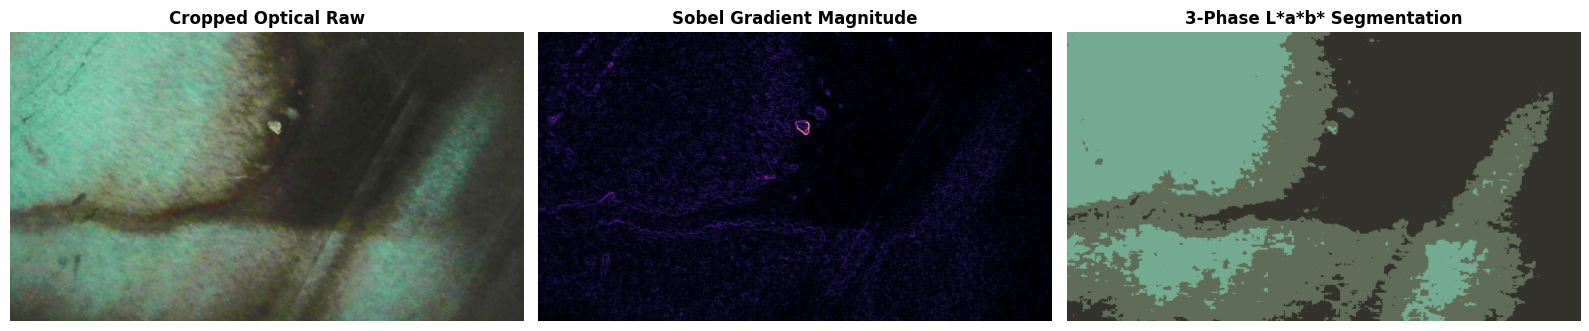

Phase 1 (RGB: [95, 108, 87]): 32.39%
Phase 2 (RGB: [51, 51, 44]): 37.79%
Phase 3 (RGB: [116, 170, 143]): 29.81%


In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Load test frame
img_path = "data/raw/banded_agate_sulaiman/bas_001.png"
img = cv2.imread(img_path)
if img is None:
    import glob
    img = cv2.imread(sorted(glob.glob("data/raw/banded_agate_sulaiman/*.png"))[0])

# Crop 10% perimeter to eliminate the corner card reflection/vignette
h, w = img.shape[:2]
crop = img[int(h*0.1):int(h*0.9), int(w*0.1):int(w*0.9)]
crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)

# 2. Check Edge Detection (Sobel Gradients)
gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
mag = cv2.magnitude(gx, gy)

# 3. 3-Phase Color Clustering in L*a*b*
lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB).astype(np.float32)
# Lightness 0.6, chromatic channels amplified
weights = np.array([0.6, 2.0, 2.0], dtype=np.float32)
weighted_px = (lab * weights).reshape(-1, 3)

k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
labels = kmeans.fit_predict(weighted_px)

# Reconstruct RGB colors
centers_rgb = np.zeros((k, 3), dtype=np.uint8)
flat_rgb = crop_rgb.reshape(-1, 3)
for i in range(k):
    mask = (labels == i)
    if np.any(mask):
        centers_rgb[i] = np.mean(flat_rgb[mask], axis=0).astype(np.uint8)

segmented_rgb = centers_rgb[labels].reshape(crop.shape)

# 4. Display Diagnostics
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
axs[0].imshow(crop_rgb)
axs[0].set_title("Cropped Optical Raw", fontweight='bold')
axs[0].axis('off')

axs[1].imshow(mag, cmap='magma')
axs[1].set_title("Sobel Gradient Magnitude", fontweight='bold')
axs[1].axis('off')

axs[2].imshow(segmented_rgb)
axs[2].set_title("3-Phase L*a*b* Segmentation", fontweight='bold')
axs[2].axis('off')

plt.tight_layout()
plt.show()

counts = np.bincount(labels, minlength=k)
pcts = (counts / counts.sum()) * 100
for i in range(k):
    print(f"Phase {i+1} (RGB: {centers_rgb[i].tolist()}): {pcts[i]:.2f}%")

## Specimen SPEC-0004: Akik Sulaiman Karang (Scenic Dendritic Chalcedony)

### 1. Transmitted Reflector Illumination Diagnostics
* **Backlight Diffusion Solution:** Introducing a planar white diffuse card beneath the cabochon resolved sensor starvation caused by internal light scattering within translucent chalcedony.
* **Phase Stratification (Balanced 3-Phase Domain):**
  * **Translucent Mint Chalcedony Core (Phase 3, 29.81%):** High-luminance microcrystalline silica body (`RGB: [116, 170, 143]`).
  * **Oxidation Contact Margin / Halo (Phase 1, 32.39%):** Iron-bearing alteration ribbon defining scenic contour lines (`RGB: [95, 108, 87]`).
  * **Dark Inclusion Groundmass (Phase 2, 37.79%):** Low-reflectance dendrite/matrix body (`RGB: [51, 51, 44]`).

### 2. Boundary Gradient Extraction
* Sobel gradient magnitude cleanly delineates the curvilinear contact channel, demonstrating that non-banded scenic chalcedony displays continuous boundary contours rather than discrete periodic striation harmonics.

In [10]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
from skimage.feature import graycomatrix, graycoprops
from sklearn.cluster import KMeans

raw_dir = "data/raw/banded_agate_sulaiman"
files = sorted(glob.glob(os.path.join(raw_dir, "bas_*.png")))

records = []
for p in files:
    img = cv2.imread(p)
    if img is None:
        continue
    
    # Crop outer 10% border to eliminate card reflection spill
    h, w = img.shape[:2]
    crop = img[int(h*0.1):int(h*0.9), int(w*0.1):int(w*0.9)]
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    
    # 1. Texture Metrics (GLCM)
    patch = gray[gray.shape[0]//4:3*gray.shape[0]//4, gray.shape[1]//4:3*gray.shape[1]//4]
    glcm = graycomatrix(patch, distances=[1], angles=[0, np.pi/4, np.pi/2], levels=256, symmetric=True, normed=True)
    contrast = float(graycoprops(glcm, 'contrast').mean())
    homogeneity = float(graycoprops(glcm, 'homogeneity').mean())
    
    # 2. Gradient Edge Intensity
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    mag = cv2.magnitude(gx, gy)
    mean_edge_grad = float(np.mean(mag))
    
    # 3. 3-Phase Segmentation
    lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = np.array([0.6, 2.0, 2.0], dtype=np.float32)
    weighted_px = (lab * weights).reshape(-1, 3)
    
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    labels = kmeans.fit_predict(weighted_px)
    counts = np.bincount(labels, minlength=3)
    pcts = (counts / counts.sum()) * 100.0
    
    # Identify phases by lightness / color
    cluster_means = [np.mean(crop_rgb.reshape(-1, 3)[labels == i], axis=0) for i in range(3)]
    # Dark matrix: lowest R+G+B sum
    dark_idx = int(np.argmin([np.sum(m) for m in cluster_means]))
    # Mint chalcedony: highest green channel
    mint_idx = int(np.argmax([m[1] for m in cluster_means]))
    # Alteration rim: remaining cluster
    rim_idx = [i for i in range(3) if i not in (dark_idx, mint_idx)][0]
    
    records.append({
        "specimen_id": "SPEC-0004",
        "mineral_name": "Akik Sulaiman Karang (Scenic Chalcedony)",
        "filename": os.path.basename(p),
        "glcm_contrast": round(contrast, 2),
        "glcm_homogeneity": round(homogeneity, 3),
        "mean_edge_gradient": round(mean_edge_grad, 2),
        "pct_dark_matrix": round(float(pcts[dark_idx]), 2),
        "pct_alteration_halo": round(float(pcts[rim_idx]), 2),
        "pct_translucent_chalcedony": round(float(pcts[mint_idx]), 2)
    })

df_karang = pd.DataFrame(records)
df_karang.to_csv("akik_karang_characterization.csv", index=False)
print(f"Extracted {len(df_karang)} records for SPEC-0004. Saved to akik_karang_characterization.csv")

Extracted 10 records for SPEC-0004. Saved to akik_karang_characterization.csv


In [11]:
import json

# 1. Append records to docs/data.json
with open("docs/data.json", "r") as f:
    master_data = json.load(f)

# Clear any prior runs of SPEC-0004
master_data = [row for row in master_data if row.get("specimen_id") != "SPEC-0004"]
master_data.extend(df_karang.to_dict(orient="records"))

with open("docs/data.json", "w") as f:
    json.dump(master_data, f, indent=2)

# 2. Make representative web thumbnail from bas_001
best_frame = "data/raw/banded_agate_sulaiman/bas_001.png"
img_thumb = cv2.imread(best_frame)
h, w = img_thumb.shape[:2]
crop_thumb = img_thumb[int(h*0.1):int(h*0.9), int(w*0.1):int(w*0.9)]
scale = 480.0 / crop_thumb.shape[1]
thumb_resized = cv2.resize(crop_thumb, (480, int(crop_thumb.shape[0] * scale)), interpolation=cv2.INTER_AREA)

cv2.putText(thumb_resized, "SPEC-0004 / AKIK KARANG TUNGGAL", (15, thumb_resized.shape[0] - 15),
            cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 1, cv2.LINE_AA)
cv2.imwrite("docs/assets/thumbnails/specimen_0004_thumb.jpg", thumb_resized, [cv2.IMWRITE_JPEG_QUALITY, 80])

print("docs/data.json updated and thumbnail generated at docs/assets/thumbnails/specimen_0004_thumb.jpg")

docs/data.json updated and thumbnail generated at docs/assets/thumbnails/specimen_0004_thumb.jpg
